# 07 · Spiral phase and vortex beams: build it step by step

A vortex beam carries an azimuthal phase winding. Its phase is singular at the center, and propagation reveals the characteristic dark core and ring-shaped intensity.

This companion develops the same idea with small functions defined beside the experiment that needs them.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt


## 1. Set the coordinates for a transverse field

`meshgrid` gives each pixel its `(x,y)` location. Radius controls the envelope, while polar angle will set the phase winding.

In [ ]:
lambda_m = 500e-9
window_m = 2e-3
n = 512
x_m = np.linspace(-window_m/2, window_m/2, n, endpoint=False)
X, Y = np.meshgrid(x_m, x_m)
r = np.hypot(X, Y)
theta = np.arctan2(Y, X)
envelope = np.exp(-(r/150e-6)**2)


## 3. Define the 2D propagator

The field has two transverse coordinates, so both spatial-frequency axes enter the transfer function.

In [ ]:
def propTF2(field, window_x_m, window_y_m, wavelength_m, z_m):
    """Paraxial Fresnel propagation of a 2D field."""
    ny, nx = field.shape
    fx = np.fft.fftshift(np.fft.fftfreq(nx, d=window_x_m/nx))
    fy = np.fft.fftshift(np.fft.fftfreq(ny, d=window_y_m/ny))
    FX, FY = np.meshgrid(fx, fy)
    transfer = np.exp(-1j*np.pi*wavelength_m*z_m*(FX**2+FY**2))
    spectrum = np.fft.fftshift(np.fft.fft2(np.fft.ifftshift(field)))
    return np.fft.fftshift(np.fft.ifft2(np.fft.ifftshift(spectrum*transfer)))


## 2. Define a vortex phase mask

Multiplying by `exp(i ℓ θ)` winds the phase by `2πℓ` around the center. For nonzero integer charge, the field must vanish at the singular center.

In [ ]:
def vortex_field(envelope, theta, charge):
    """Apply an azimuthal phase winding to an amplitude envelope."""
    return envelope*np.exp(1j*charge*theta)

charge = 1
field0 = vortex_field(envelope, theta, charge)


## 3. Use the package 2D Fresnel propagator

The scalar 1D propagator cannot act on a two-dimensional field. `propTF2` handles both axes and their frequency coordinates.

In [ ]:
field_z = propTF2(field0, window_m, window_m, lambda_m, 0.05)


## Original plot code (verbatim)

The following code cells and saved outputs are copied unchanged from the cited notebook cells. Some source cells rely on variables established earlier in their original notebook.


From `paper/20260407SpiralBeamsPt2 copy.ipynb`, cell 5.


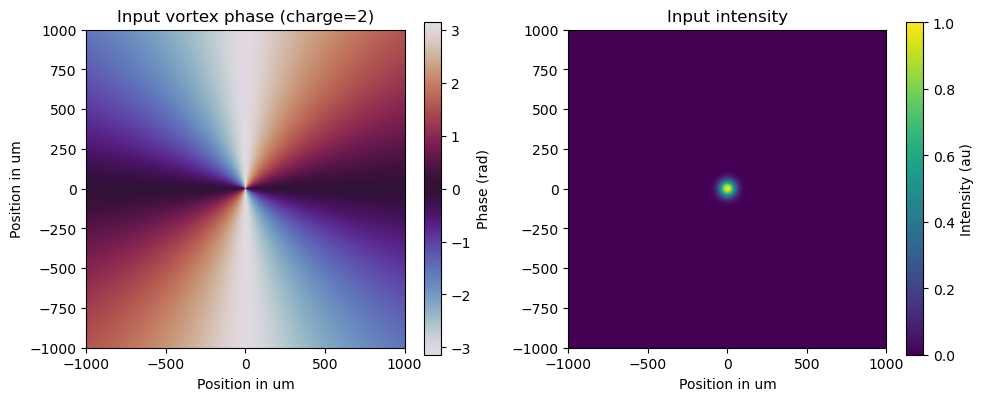

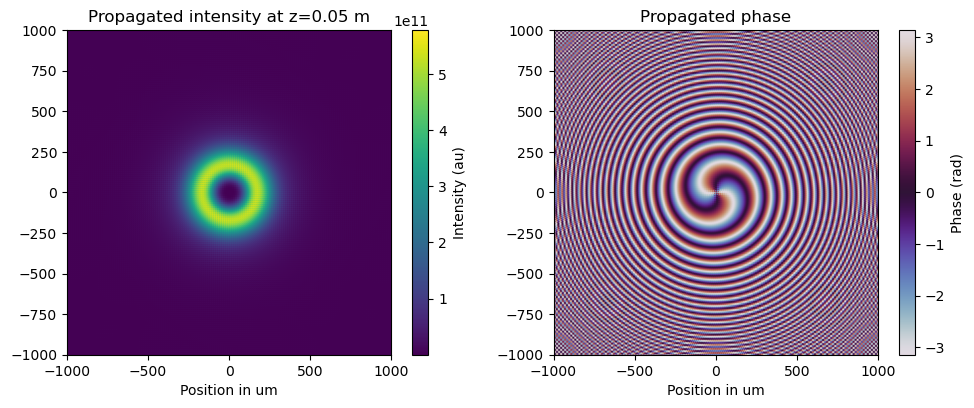

In [6]:
# generate a spiral (vortex) phase and propagate the vortex beam
charge = 2  # topological charge (try -1, 2, 3, ...)

# compute azimuthal angle
X, Y = np.meshgrid(x_m, y_m) #2D grid
theta = np.arctan2(Y, X)  #arctan is good way to get azimuthl ramp of phase  

spiral_phase = np.exp(1j * charge * theta)
vortex = uin_V_m * spiral_phase  # multiply by current amplitude (uin_V_m from earlier cell)


# copilot helped but don't fully understand ^ 


plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.imshow(np.angle(vortex), extent=[x_m[0]*1e6, x_m[-1]*1e6, y_m[0]*1e6, y_m[-1]*1e6],
           origin='lower', cmap='twilight')
plt.title(f"Input vortex phase (charge={charge})")
plt.xlabel("Position in um")
plt.ylabel("Position in um")
plt.colorbar(label="Phase (rad)")

plt.subplot(1,2,2)
plt.imshow(np.abs(vortex)**2, extent=[x_m[0]*1e6, x_m[-1]*1e6, y_m[0]*1e6, y_m[-1]*1e6],
           origin='lower')
plt.title("Input intensity")
plt.xlabel("Position in um")
plt.colorbar(label="Intensity (au)")
plt.tight_layout()
plt.show()


z_prop_m = 0.05  
wavelength = 500e-9

field_out = propTF(vortex, Dx_m, wavelength, z_prop_m)


plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.imshow(np.abs(field_out)**2, extent=[x_m[0]*1e6, x_m[-1]*1e6, y_m[0]*1e6, y_m[-1]*1e6],
           origin='lower')
plt.title(f"Propagated intensity at z={z_prop_m} m")
plt.xlabel("Position in um")
plt.colorbar(label="Intensity (au)")

plt.subplot(1,2,2)
plt.imshow(np.angle(field_out), extent=[x_m[0]*1e6, x_m[-1]*1e6, y_m[0]*1e6, y_m[-1]*1e6],
           origin='lower', cmap='twilight')
plt.title("Propagated phase")
plt.xlabel("Position in um")
plt.colorbar(label="Phase (rad)")

plt.tight_layout()
plt.show()

From `paper/20260407SpiralBeamsPt2 copy.ipynb`, cell 9.


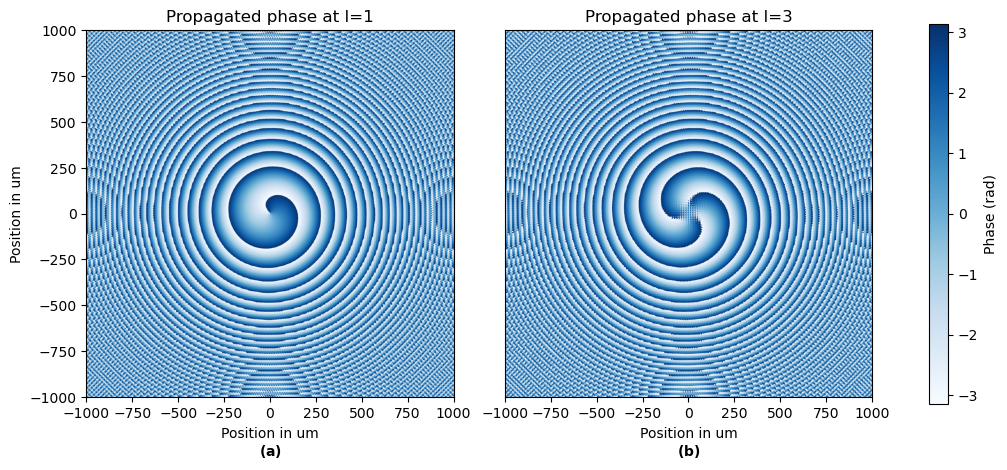

In [12]:
import matplotlib.pyplot as plt
import numpy as np

# Common parameters
extent_um = [x_m[0]*1e6, x_m[-1]*1e6, y_m[0]*1e6, y_m[-1]*1e6]
z_prop_m = 0.05  
wavelength = 500e-9

# 2D coordinate grid and azimuthal angle
X, Y = np.meshgrid(x_m, y_m)
theta = np.arctan2(Y, X)

# --- Compute field for l = 1 ---
charge1 = 1
vortex1 = uin_V_m * np.exp(1j * charge1 * theta)
field_out1 = propTF(vortex1, Dx_m, wavelength, z_prop_m)

# --- Compute field for l = 3 ---
charge2 = 3
vortex2 = uin_V_m * np.exp(1j * charge2 * theta)
field_out2 = propTF(vortex2, Dx_m, wavelength, z_prop_m)

# --- Plot side-by-side using constrained layout ---
fig, axs = plt.subplots(1, 2, figsize=(10, 4.5), layout='constrained')

# Left plot: l = 1
im1 = axs[0].imshow(np.angle(field_out1), extent=extent_um, origin='lower', cmap='Blues')
axs[0].set_title("Propagated phase at l=1")
axs[0].set_xlabel("Position in um\n$\\bf{(a)}$")
axs[0].set_ylabel("Position in um")

# Right plot: l = 3
im2 = axs[1].imshow(np.angle(field_out2), extent=extent_um, origin='lower', cmap='Blues')
axs[1].set_title("Propagated phase at l=3")
axs[1].set_xlabel("Position in um\n$\\bf{(b)}$")
axs[1].tick_params(left=False, labelleft=False)

# Add single colorbar pinned outside to the right
fig.colorbar(im2, ax=axs, location='right', label="Phase (rad)")

plt.show()